# **Registro de Imágenes de Resonancia Magnética (T1 y DTI)**

---

## **1. Fundamentos Teóricos del Registro de Imágenes y Parámetros de Adquisición**

El registro de imágenes médicas es el proceso de alinear espacialmente dos o más volúmenes de imágenes en un sistema de coordenadas común. En la caracterización de gliomas, la integración de la anatomía de alta resolución (**T1 FSPGR (Fast Spoiled Gradient Echo) 3D**) con la información microestructural de difusometría (**DTI**) permite mapear la relación entre la masa tumoral y los tractos de sustancia blanca.

---

### **1.1. Parámetros de Adquisición y Geometría del Vóxel**

* **Patient Position (Posición del Paciente):** Define la orientación espacial del paciente dentro del gantry del resonador (por ejemplo, `HFS`: *Head First Supine*). Establece el sistema de referencia para las direcciones anatómicas:
  * **Anterior - Posterior (A-P)**
  * **Superior - Inferior (S-I)**
  * **Left - Right (L-R)** (sistemas informáticos suelen usar convenciones **RAS** o **LPS**).

* **Pixel Size y Voxel Size (Tamaño de Vóxel y Espaciado):**
  * **T1 3D (FSPGR/MPRAGE):** Adquisición isotrópica de alta resolución (ejemplo: 1.0 x 1.0 x 1.0 mm³).
  * **DTI (EPI - Echo Planar Imaging):** Resolución espacial menor (ejemplo: 2.0 x 2.0 x 2.0 mm³ o espesores de corte mayores a 2 mm) para compensar la baja relación señal-ruido (SNR).

* **Matriz Affine y Sistema Coordenado ($SFORM / QFORM$):**
  La matriz $A$ de $4 \times 4$ codifica la transformación desde el espacio discreto de índices de vóxeles $(i, j, k)$ hasta el espacio contiguo físico en milímetros $(x, y, z)$:

$$\begin{pmatrix} x \\ y \\ z \\ 1 \end{pmatrix} = A \begin{pmatrix} i \\ j \\ k \\ 1 \end{pmatrix} = \begin{pmatrix} s_{11} & s_{12} & s_{13} & o_x \\ s_{21} & s_{22} & s_{23} & o_y \\ s_{31} & s_{32} & s_{33} & o_z \\ 0 & 0 & 0 & 1 \end{pmatrix} \begin{pmatrix} i \\ j \\ k \\ 1 \end{pmatrix}$$

Donde $(o_x, o_y, o_z)$ representa el origen del volumen en el espacio del escáner y la submatriz de $3 \times 3$ contiene la escala (tamaño del vóxel) y las rotaciones del plano de adquisición.

---

### **1.2. Transformaciones Rígidas y Afines (Matrices de Rotación y Traslación)**

El registro rígido preserva las distancias e incluye 6 grados de libertad (3 rotaciones y 3 traslaciones).

#### **Matrices de Rotación Tridimensional:**
Rotaciones según el orden de Euler alrededor de los ejes $X$, $Y$ y $Z$:

$$R_x(\alpha) = \begin{pmatrix} 1 & 0 & 0 \\ 0 & \cos\alpha & -\sin\alpha \\ 0 & \sin\alpha & \cos\alpha \end{pmatrix}, \quad R_y(\beta) = \begin{pmatrix} \cos\beta & 0 & \sin\beta \\ 0 & 1 & 0 \\ -\sin\beta & 0 & \cos\beta \end{pmatrix}, \quad R_z(\gamma) = \begin{pmatrix} \cos\gamma & -\sin\gamma & 0 \\ \sin\gamma & \cos\gamma & 0 \\ 0 & 0 & 1 \end{pmatrix}$$

La matriz de rotación compuesta es:

$$R = R_z(\gamma) R_y(\beta) R_x(\alpha)$$

#### **Vector de Traslación:**

$$T = \begin{pmatrix} t_x \\ t_y \\ t_z \end{pmatrix}$$

#### **Matriz Homogénea Rígida ($4 \times 4$):**

$$M_{\text{rígida}} = \begin{pmatrix} R_{3\times 3} & T_{3\times 1} \\ 0_{1\times 3} & 1 \end{pmatrix} = \begin{pmatrix} r_{11} & r_{12} & r_{13} & t_x \\ r_{21} & r_{22} & r_{23} & t_y \\ r_{31} & r_{32} & r_{33} & t_z \\ 0 & 0 & 0 & 1 \end{pmatrix}$$

> **Nota:** La transformación afín extiende esta matriz agregando 3 factores de escala ($s_x, s_y, s_z$) y 3 factores de cizallamiento (*shear*), sumando 12 grados de libertad para corregir ligeras distorsiones globales.

---

### **1.3. ¿Por qué registrar imágenes intra-modalidad e inter-modalidad en un mismo protocolo?**

1. **Movimiento del Paciente:** Aunque las secuencias se adquieran en la misma sesión, pequeños movimientos involuntarios entre la secuencia T1 y la secuencia DTI generan desalineación espacial.
2. **Diferencias de Secuencia y Distorsión EPI:** Las secuencias de difusión son adquiridas mediante *Echo Planar Imaging* (EPI), altamente sensibles a artefactos de susceptibilidad magnética en interfaces aire-hueso (ej. senos paranasales, base de cráneo). La secuencia T1 FSPGR 3D no presenta estas distorsiones y actúa como la referencia anatómica (*Gold Standard*).
3. **Fusión para Planeación Quirúrgica:** Permite proyectar los mapas de **Fracción de Anisotropía (FA)** o la **Tractografía 3D** directamente sobre la anatomía T1 con contraste, delimitando la infiltración tumoral respecto a las vías motoras o del lenguaje.

---

### **1.4. Referencias Anatómicas: La Comisura Anterior (AC)**

<p align="center">
  <img src="https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/AC-PC.jpeg" alt="Línea AC-PC" width="500"/>
</p>

* La **Comisura Anterior (AC)** y la **Comisura Posterior (PC)** son estructuras subcorticales compactas utilizadas históricamente como origen del sistema de coordenadas anatómicas (**Línea AC-PC** o Espacio Talairach/MNI).
* En registros rígidos/afines manuales o semiautomáticos, la **AC** es elegida como el centro de transformación debido a:
  * Su ubicación central e inalterable en el cerebro (incluso en presencia de gliomas corticales).
  * En mapas de difusión o secuencias anatómicas, la densidad de fibra mielinizada o el contraste de sustancia blanca/gris permite localizarla de forma inequívoca para definir el pivote de las matrices de rotación $R$.

In [ ]:
# Instalación silenciosa de dependencias para procesamiento de imágenes médicas
!pip install -q nibabel nilearn dipy matplotlib scipy
print("Entorno configurado correctamente con NiBabel, Nilearn y DIPY.")

Entorno configurado correctamente con NiBabel, Nilearn y DIPY.


### Conceptos Fundamentales: RM Ponderada en T1 y DTI

* **Imagen Ponderada en T1 (T1w):** Secuencia anatómica estructural estándar en resonancia magnética. Ofrece un elevado contraste entre la sustancia blanca (brillante), la sustancia gris (intermedia) y el líquido cefalorraquídeo (oscuro). Con la administración de contraste (gadolinio), permite delimitar con precisión bordes tumorales, hipercaptaciones y zonas con alteración de la barrera hematoencefálica.

* **Imagen de Tensor de Difusión (DTI):** Técnica avanzada de resonancia magnética que evalúa la magnitud y direccionalidad del movimiento microscópico de las moléculas de agua. Al calcular el tensor de difusión en cada vóxel (matriz simétrica de $3 \times 3$), se obtienen sus tres autovalores principales ordenados de mayor a menor: $\lambda_1 \ge \lambda_2 \ge \lambda_3$.

#### Formulación Matemática de los 4 Mapas Derivados de DTI

1. **AD (Difusividad Axial / *Axial Diffusivity*):**
   $$\text{AD} = \lambda_1$$
   Mide la difusión paralela al eje longitudinal del axón. Es un indicador sensible a la integridad axonal.

2. **RD (Difusividad Radial / *Radial Diffusivity*):**
   $$\text{RD} = \frac{\lambda_2 + \lambda_3}{2}$$
   Mide la difusión perpendicular al eje principal de las fibras. Se relaciona directamente con la integridad de la vaina de mielina y el empaquetamiento axonal.

3. **MD (Difusividad Media / *Mean Diffusivity*):**
   $$\text{MD} = \bar{\lambda} = \frac{\lambda_1 + \lambda_2 + \lambda_3}{3}$$
   Mide el promedio global de difusividad en todas las direcciones. Incrementa cuando hay edema extracelular o desintegración celular.

4. **FA (Anisotropía Fraccional / *Fractional Anisotropy*):**
   $$\text{FA} = \sqrt{\frac{3}{2}} \frac{\sqrt{(\lambda_1 - \bar{\lambda})^2 + (\lambda_2 - \bar{\lambda})^2 + (\lambda_3 - \bar{\lambda})^2}}{\sqrt{\lambda_1^2 + \lambda_2^2 + \lambda_3^2}}$$
   Cuantifica el grado de direccionalidad de la difusión en una escala de 0 a 1 ($0 \le \text{FA} \le 1$). Presenta valores altos en tractos sanos y altamente mielinizados, y valores cercanos a 0 en medio isótropo (líquido cefalorraquídeo o tejido desorganizado).

> **Relevancia Quirúrgica en Neuro-Oncología**
>
> La fusión de T1 con contraste y mapas DTI (FA) permite al neurocirujano clasificar el compromiso de los tractos de sustancia blanca adyacentes al glioma en tres patrones:
> 1. **Desplazamiento:** El tracto conserva valores de FA normales pero cambia su trayectoria anatómica por el efecto de masa tumoral.
> 2. **Edema vasogénico:** La FA disminuye ligeramente debido al incremento de agua libre extracelular, pero la orientación direccional se preserva.
> 3. **Infiltración / Destrucción:** Pérdida severa de la FA y desorganización direccional, indicando invasión tumoral directa del haz corticoespinal o fascículo arqueado.

![Mapas DTI y T1](https://raw.githubusercontent.com/pamelaFranco/Laboratorio-Imagenes/main/imagenes/Fig1.png)

> **Relevancia Quirúrgica en Neuro-Oncología**
>
> La fusión de T1 con contraste y mapas DTI (FA) permite al neurocirujano clasificar el compromiso de los tractos de sustancia blanca adyacentes al glioma en tres patrones:
> 1. **Desplazamiento:** El tracto conserva valores de FA normales pero cambia su trayectoria anatómica por el efecto de masa tumoral.
> 2. **Edema vasogénico:** La FA disminuye ligeramente debido al incremento de agua libre extracelular, pero la orientación direccional se preserva.
> 3. **Infiltración / Destrucción:** Pérdida severa de la FA y desorganización direccional, indicando invasión tumoral directa del haz corticoespinal o fascículo arqueado.

### Parámetros de Adquisición de Secuencias MRI

**Resonador Magnético:** General Electric 1.5 T (Signa HDxt) con bobina de cabeza de 8 canales.

---

#### 1. Secuencia Estructural T1-Weighted (3D T1w)
* **Tiempo de Adquisición:** 4 min 8 s
* **Tiempo de Eco (TE):** 1.9 ms
* **Tiempo de Repetición (TR):** 6.1 ms
* **Ángulo de Inclinación (Flip Angle):** 12°
* **Matriz de Adquisición:** 256 × 256
* **Campo de Visión (FOV):** 24 cm
* **Grosor de Corte (Slice Thickness):** 1.2 mm (312 cortes)
* **Tamaño de Vóxel Reconstruido:** 0.94 × 0.94 × 1.20 mm³

---

#### 2. Secuencia de Difusión DTI (para Mapa de FA)
* **Secuencia:** Single-shot spin-echo echo-planar imaging (EPI)
* **Tiempo de Adquisición:** 5 min 12 s
* **Tiempo de Eco (TE):** 96.2 ms
* **Tiempo de Repetición (TR):** 12,000 ms
* **Ángulo de Inclinación (Flip Angle):** 90°
* **Valor b (b-value):** 1000 s/mm²
* **Direcciones de Difusión:** 25 direcciones no colineales + 1 imagen sin ponderación ($b_0$)
* **Matriz de Adquisición:** 128 × 128
* **Matriz Reconstruida:** 256 × 256 (Resolución en el plano: 0.94 × 0.94 mm²)
* **Grosor de Corte:** 5 mm (sin espacio intercorte, cobertura cerebral completa)
* **Resolución Re-muestreada (Preprocesamiento):** Vóxeles isotrópicos de 2 × 2 × 2 mm³

## **2. Descarga del Dataset y Carga de Volúmenes**

Cargamos la imagen anatómica T1 (FSPGR 3D) y el mapa de difusión (FA) provenientes del conjunto de datos.

In [ ]:
import os
import nibabel as nib
import numpy as np

# URL base del repositorio de datos
base_url = "https://raw.githubusercontent.com/pamelaFranco/workshop_glioma/main/Dataset/DATOS_ANONIMIZADOS_WORKSHOP/"

# Archivos objetivo: T1 Anatómico y Mapa DTI (FA / b0)
files = {
    "T1_anat": "Sujeto01_Ax_FSPGR_3D_N.nii.gz",
    "DTI_FA": "Sujeto01_s08.src.gz.dti.fib.gz.fa.nii.gz"
}

# Descargar archivos si no existen localmente
for key, file_name in files.items():
    if not os.path.exists(file_name):
        url = base_url + file_name
        !wget -q --show-progress {url} -O {file_name}

# Carga de objetos NIfTI
img_t1 = nib.load(files["T1_anat"])
img_fa = nib.load(files["DTI_FA"])

print(f"T1 Shape: {img_t1.shape} | Voxel Size: {img_t1.header.get_zooms()[:3]}")
print(f"FA Shape: {img_fa.shape} | Voxel Size: {img_fa.header.get_zooms()[:3]}")

Sujeto01_Ax_FSPGR_3 100%[===================>]   7.69M  --.-KB/s    in 0.1s    
Sujeto01_s08.src.gz 100%[===================>] 984.75K  --.-KB/s    in 0.05s   
T1 Shape: (157, 189, 156) | Voxel Size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
FA Shape: (78, 94, 68) | Voxel Size: (np.float32(2.0), np.float32(2.0), np.float32(2.0))


## **Control de Calidad Visual: Inspección en Damero (Checkerboard)**

Para validar cuantitativamente o visualmente la precisión del alineamiento antes de proceder a la tractografía, se suele utilizar la visualización en **damero (Checkerboard)**, la cual alterna bloques rectangulares de la imagen de referencia (T1) y la imagen flotante (FA).

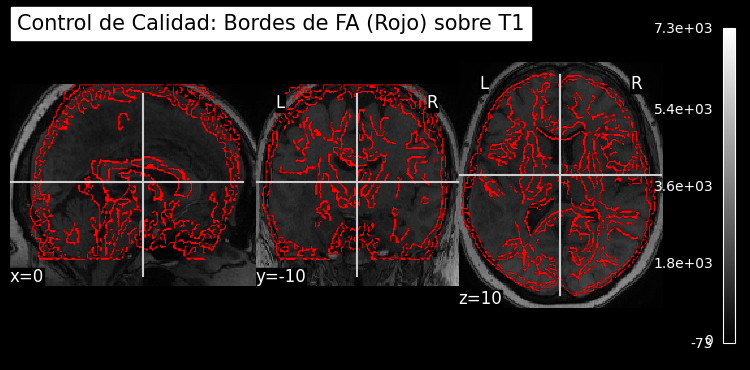

In [ ]:
from nilearn import image, plotting

# 1. Re-muestrear la imagen FA al espacio y resolución de la T1
img_fa_resampled = image.resample_to_img(source_img=img_fa, target_img=img_t1)

# 2. Generar la visualización anatómica
display = plotting.plot_anat(
    img_t1,
    cut_coords=(0, -10, 10),
    title="Control de Calidad: Bordes de FA (Rojo) sobre T1",
)

# 3. Superponer los bordes de la FA re-muestreada
display.add_edges(img_fa_resampled)

plotting.show()

## **3. Exploración Geométrica: Matrices Affine ($SFORM/QFORM$)**

Inspección de las matrices de conversión vóxel-a-mundo de ambas modalidades antes de aplicar el registro.

In [ ]:
print("--- MATRIZ AFFINE T1 (FSPGR 3D) ---")
print(np.round(img_t1.affine, 2))

print("\n--- MATRIZ AFFINE DTI (FA) ---")
print(np.round(img_fa.affine, 2))

--- MATRIZ AFFINE T1 (FSPGR 3D) ---
[[  -1.    0.    0.   78.]
 [   0.    1.    0. -112.]
 [   0.    0.    1.  -70.]
 [   0.    0.    0.    1.]]

--- MATRIZ AFFINE DTI (FA) ---
[[ -2.     0.     0.    77.  ]
 [  0.    -2.     0.    70.28]
 [  0.     0.     2.   -49.46]
 [  0.     0.     0.     1.  ]]


## **4. Alineación Espacial Basada en Encabezados ($SFORM / QFORM$)**

Dado que las secuencias T1 FSPGR y DTI se adquirieron en la misma sesión clínica, sus encabezados NIfTI integran las coordenadas físicas reales del resonador.

Para integrar ambas modalidades no se requiere optimizar una nueva matriz de registro; únicamente se realiza un **re-muestreo tridimensional** para interpolar la resolución del mapa de FA ($2.0 \text{ mm}$) a la grilla anatómica de alta resolución del T1 ($1.0 \text{ mm}$).

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting
from nilearn.image import resample_to_img

# Re-muestreo directo de la imagen FA al espacio y resolución de la T1
img_fa_resampled = resample_to_img(
    source_img=img_fa,
    target_img=img_t1,
    interpolation='continuous'
)

print("¡Re-muestreo completado con éxito!")
print(f"Dimensiones T1 origen:      {img_t1.shape}")
print(f"Dimensiones FA re-muestreada: {img_fa_resampled.shape}")

¡Re-muestreo completado con éxito!
Dimensiones T1 origen:      (157, 189, 156)
Dimensiones FA re-muestreada: (157, 189, 156)


> **Tip de Procesamiento: Interpolación Continua vs. Nearest Neighbor**
>
> Al utilizar `resample_to_img` o herramientas como ANTs/FSL, la elección del algoritmo de interpolación es crítica:
> * **`continuous` (Trilineal o B-Spline):** Debe usarse para mapas escalares continuos como **FA, MD, ADC o mapas T1/T2**, ya que calcula promedios ponderados entre vóxeles vecinos para preservar la suavidad del tejido.
> * **`nearest` (Vecino más cercano):** **Obligatorio** cuando se re-muestren **máscaras de segmentación anatómica o tumoral (ROIs)**. Utilizar interpolación continua en una máscara binaria (valores 0 y 1) generará bordes difusos con valores intermedios, alterando el volumen real de la lesión.

## **5. Limpieza de Fondo y Evaluación de Distorsión EPI**

Para corregir la visualización:
1. Enmascaramos los valores de fondo de la FA para volverlos transparentes (eliminando el recuadro rojo exterior).
2. Evaluamos la **distorsión no lineal EPI** comparando la sustancia blanca real contra el borde de la T1 (línea cian).

/tmp/ipykernel_1220/1937933272.py:34: UserWarning: Non-finite values detected. These values will be replaced with zeros.
  display.add_overlay(img_fa_clean, cmap='hot', alpha=0.75, threshold=threshold_val)
/tmp/ipykernel_1220/1937933272.py:34: UserWarning: kwargs['alpha']=0.75 detected in parameters.
Overriding with transparency=None.
To suppress this warning pass your 'alpha' value via the 'transparency' parameter.
  display.add_overlay(img_fa_clean, cmap='hot', alpha=0.75, threshold=threshold_val)


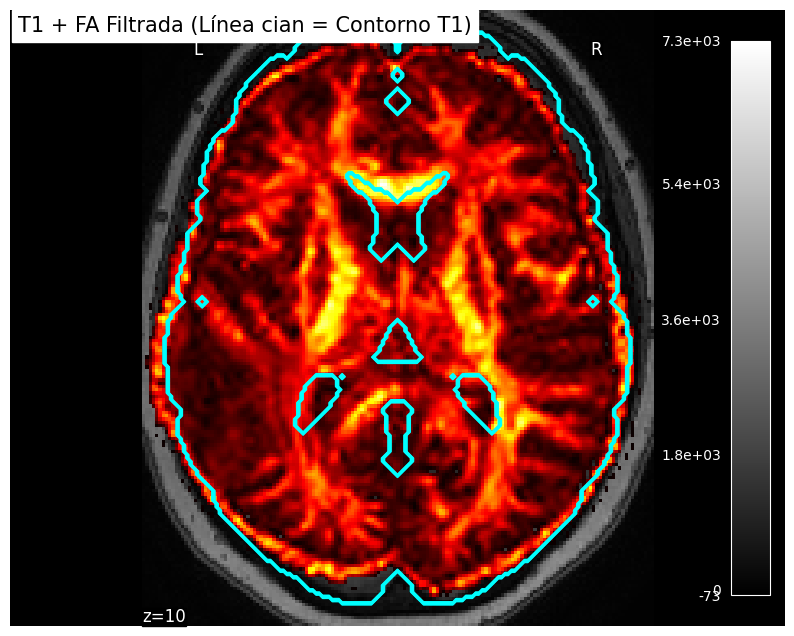

In [ ]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting
from nilearn.masking import compute_brain_mask

# 1. Obtener la máscara cerebral de la T1
brain_mask_t1 = compute_brain_mask(img_t1)

# 2. Filtrar el fondo de la FA para eliminar el recuadro rojo
fa_data = img_fa_resampled.get_fdata().copy()

# Definir un umbral para eliminar el fondo/ruido (valores bajos)
threshold_val = np.percentile(fa_data[fa_data > 0], 25)
fa_data[fa_data < threshold_val] = np.nan  # Convertir fondo en transparente

# Crear volumen NIfTI limpio
img_fa_clean = nib.Nifti1Image(fa_data, img_fa_resampled.affine)

# 3. Visualización corregida
fig, ax = plt.subplots(figsize=(10, 8))

display = plotting.plot_anat(
    img_t1,
    display_mode='z',
    cut_coords=[10],
    title="T1 + FA Filtrada (Línea cian = Contorno T1)",
    figure=fig,
    axes=ax
)

# Dibujar el contorno del cerebro T1 y superponer la FA limpia
display.add_contours(brain_mask_t1, colors='cyan', linewidths=1.2)
display.add_overlay(img_fa_clean, cmap='hot', alpha=0.75, threshold=threshold_val)

plt.show()

### **Nota Clínica sobre Artefactos de Susceptibilidad Magnética (EPI)**

El re-muestreo mediante matrices $SFORM/QFORM$ asume que ambas secuencias comparten una geometría rígida perfecta. Sin embargo, las secuencias DTI se adquieren mediante lectura **EPI (Echo Planar Imaging)**, la cual sufre de **distorsiones de susceptibilidad magnética no lineales** en las interfaces aire-hueso (senos paranasales, peñasco del temporal y base del cráneo).

* **Consecuencia:** Aunque la alineación global basada en el cabezal sea correcta, puede existir un desalineamiento local no rígido (estiramiento o compresión) en la zona tumoral o cortical.
* **Solución en Protocolos Quirúrgicos:** Para corregir estas distorsiones locales antes de la navegación intraoperatoria, se recomienda aplicar un algoritmo de **Registro No Rígido / Deformable** (por ejemplo, *Symmetric Normalization - SyN* de DIPY/ANTs) o corrección basada en mapas de campo ($B_0$ *fieldmaps*).

## **6. Fusión Anatómica con Extracción de Cráneo en T1**

Para igualar la extensión visual entre ambas secuencias, removemos el tejido no cerebral de la T1 (cuero cabelludo, grasa y cráneo) mediante `compute_brain_mask`. De esta forma, la anatomía T1 y el mapa de FA comparten exactamente los mismos límites bordes.

/tmp/ipykernel_1220/188171696.py:44: UserWarning: Non-finite values detected. These values will be replaced with zeros.
  display.add_overlay(img_fa_clean, cmap='hot', alpha=0.65)
/tmp/ipykernel_1220/188171696.py:44: UserWarning: kwargs['alpha']=0.65 detected in parameters.
Overriding with transparency=None.
To suppress this warning pass your 'alpha' value via the 'transparency' parameter.
  display.add_overlay(img_fa_clean, cmap='hot', alpha=0.65)


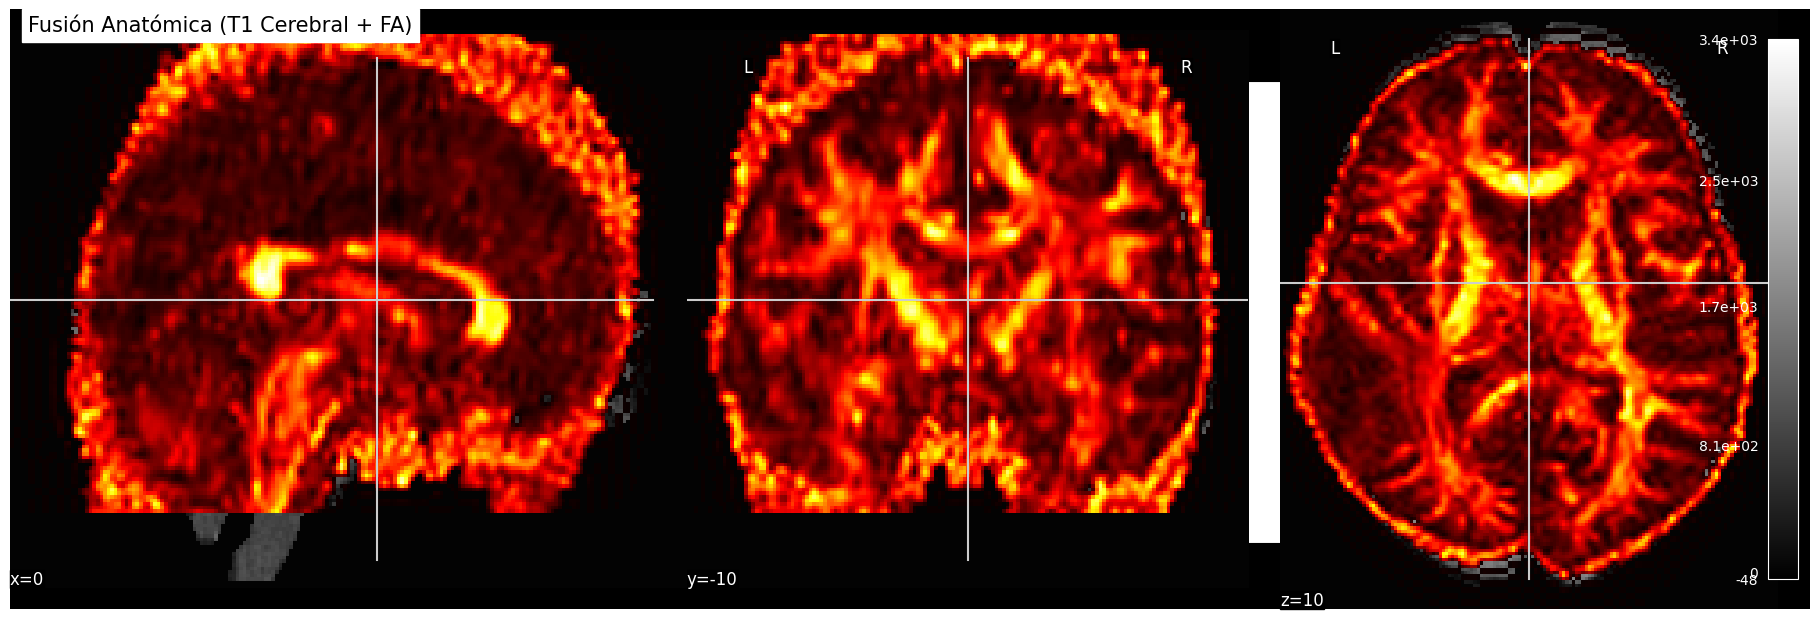

In [ ]:
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting
from nilearn.image import resample_to_img
from nilearn.masking import compute_brain_mask

# 1. Re-muestreo nativo de la FA al espacio T1
img_fa_resampled = resample_to_img(
    source_img=img_fa,
    target_img=img_t1,
    interpolation='continuous'
)

# 2. Generar máscara cerebral de la T1 y aplicarla para remover el cráneo
brain_mask = compute_brain_mask(img_t1)
t1_brain_data = img_t1.get_fdata() * brain_mask.get_fdata()
img_t1_brain = nib.Nifti1Image(t1_brain_data, img_t1.affine)

# 3. Limpiar el fondo del mapa de FA
fa_data = img_fa_resampled.get_fdata().copy()
fa_data = np.nan_to_num(fa_data)

# Filtrar ruido de fondo (valores por debajo del percentil 10 positivo)
positive_voxels = fa_data[fa_data > 0]
if len(positive_voxels) > 0:
    bg_thresh = np.percentile(positive_voxels, 10)
    fa_data[fa_data <= bg_thresh] = np.nan

img_fa_clean = nib.Nifti1Image(fa_data, img_t1.affine)

# 4. Visualización alineada sin cráneo
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

display = plotting.plot_anat(
    img_t1_brain,
    display_mode='ortho',
    cut_coords=(0, -10, 10),
    title="Fusión Anatómica (T1 Cerebral + FA)",
    figure=fig
)

# Superponer mapa FA limpio
display.add_overlay(img_fa_clean, cmap='hot', alpha=0.65)

plt.show()

# **Consideraciones Metodológicas para el Registro y Fusión T1 vs DTI (FA)**

---

## **1. Coordenadas Espaciales y Re-muestreo Nativo ($SFORM / QFORM$)**
* **Espacio Físico Compartido:** Cuando la secuencia anatómica (**T1 3D FSPGR**) y la secuencia funcional (**DTI**) se adquieren en la misma sesión clínica, las matrices de los encabezados NIfTI ($SFORM/QFORM$) ya codifican el espacio físico real del escáner.
* **Disparidad de Resolución:** La T1 posee resolución isotrópica alta ($1.0 \times 1.0 \times 1.0 \text{ mm}^3$), mientras que el mapa DTI tiene una resolución más gruesa ($2.0 \times 2.0 \times 2.0 \text{ mm}^3$). El procedimiento estándar consiste en realizar un **re-muestreo directo por interpolación** (`resample_to_img`) proyectando el mapa DTI a la grilla de $1\text{ mm}$ de la T1.

---

## **2. Limitaciones de los Algoritmos Automáticos Rígidos / Afines**
* **Efecto de Tejidos Extra-cerebrales:** Aplicar optimizadores de registro rígido o afín (basados en *Mutual Information* o centro de masa) sobre volúmenes completos suele generar rotaciones y desalineaciones espurias.
* **Sesgo por Cráneo y Fondo:** La T1 incluye el cuero cabelludo, la grasa y el cuello, mientras que el mapa de FA sólo contiene señal dentro del parénquima cerebral. Los algoritmos de intensidad intentan hacer coincidir bordes externos no equivalentes, introduciendo inclinaciones o cizallamientos no deseados en la anatomía interna.

---

## **3. Distorsiones EPI y Campo de Visión (FOV)**
* **Artefacto de Susceptibilidad Magnética:** La adquisición DTI se realiza mediante secuencias *Echo Planar Imaging* (EPI), propensas a compresiones y deformaciones locales en interfaces aire-hueso (regiones frontal y occipital).
* **Campo de Visión Restringido:** El área de adquisición ($Field\ of\ View$) del DTI suele cortarse a la altura del cerebro, omitiendo estructuras faciales y cervicales. Esto genera bordes rectos planos en las vistas sagital y coronal que corresponden al límite del escaneo DTI y no a un error de alineación.

---

## **4. Precauciones con el Registro No Lineal (SyN) y Enmascaramiento**
* **Deformaciones Artificiales:** Intentar corregir las distorsiones EPI mediante registros difeomórficos no lineales (**SyN**) sin una extracción perfecta del cráneo deforma internamente las vías axónales, tratando de "estirarlas" hacia el cuero cabelludo de la T1.
* **Sensibilidad a Máscaras Defectuosas:** Algoritmos automáticos de extracción de cráneo (`compute_brain_mask`) pueden mutilar bordes corticales sanos. Si se utiliza una máscara defectuosa como objetivo, el algoritmo deformará destructivamente la anatomía.

---

## **5. Calibración Dinámica de Intensidad y Umbral Fisiológico**
* **Escalamiento de Datos:** En diversos entornos de procesamiento (ej. *DSI Studio*), la Fracción de Anisotropía (FA) no se almacena en el rango flotante $[0.0, 1.0]$, sino multiplicada por un factor de escala (ej. $[0, 10\,000]$).
* **Filtrado Adaptativo Proporcional:** Los umbrales numéricos fijos pueden borrar la imagen completa o saturar la visualización. La fusión radiológica óptima requiere determinar el valor máximo real de FA en el volumen y aplicar un umbral proporcional (ej. $\approx 20\%$ del máximo) sobre la **T1 anatómica intacta**, garantizando fondo transparente y destacando con precisión los tractos de sustancia blanca (cuerpo calloso, cápsula interna).

### Tip: ¿Cómo procesan esto internamente softwares como FSL o DSI Studio?

Cuando utilizas interfaces de procesamiento como DSI Studio o herramientas de línea de comandos en FSL (`flirt`/`fnirt`), el software ejecuta por detrás una secuencia de tres pasos clave:

1. **Co-registro (Alignment):** Calcula una matriz de transformación matemática (de 6, 9 o 12 grados de libertad) para alinear la imagen de difusión —generalmente la imagen $b_0$ o el mapa de FA— con el espacio anatómico de la T1.
2. **Re-muestreo (Resampling):** Aplica la matriz hallada para proyectar los vóxeles de la FA sobre la grilla espacial de la T1 mediante algoritmos de interpolación (*trilinear* o *cubic spline*). Esto es necesario porque la difusión suele adquirirse a menor resolución espacial (vóxeles de 2x2x2 mm) que la T1 (1x1x1 mm).
3. **Generación de Máscaras y Bordes:** Para el control de calidad visual, el programa calcula las diferencias de gradiente en el mapa de FA re-muestreado, aislando los contornos de tractos con alta anisotropía (como el cuerpo calloso o la cápsula interna) y superponiéndolos en color contrastante sobre la imagen T1 de alta resolución.

---

## **7. Espacio Estereotáxico de Referencia: MNI (Montreal Neurological Institute)**

![Plantilla MNI152 y Sistema de Coordenadas](https://github.com/pamelaFranco/Laboratorio-Imagenes/blob/main/imagenes/mni.png?raw=true)

---

### **7.1. ¿Qué es el Espacio MNI y qué significa?**

El **espacio MNI** (*Montreal Neurological Institute*) es un sistema de coordenadas tridimensionales ($X, Y, Z$ expresados en milímetros) estandarizado que sirve como **plantilla anatómica de referencia universal** (*template*) en neuroimagenología.

* **Significado Anatómico:** A diferencia del espacio nativo del escáner (donde el origen $(0,0,0)$ depende de la posición de la cabeza del paciente en la bobina), en el espacio MNI el punto de origen $(0,0,0)$ se fija de manera inequívoca en la **Comisura Anterior (AC)**.
* **Evolución (MNI152):** La plantilla estándar más utilizada en la actualidad es la **MNI152**, construida mediante el promediado de las resonancias magnéticas T1 de 152 sujetos jóvenes y sanos previamente alineados mediante transformaciones afines.
* **Convención de Ejes (RAS):**
  * $X > 0$: Derecha (Right)
  * $Y > 0$: Anterior (Anterior)
  * $Z > 0$: Superior (Superior)

---

### **7.2. ¿Para qué sirve el Espacio MNI?**

1. **Normalización Espacial (Estudios de Grupo):** Debido a que cada cerebro humano posee variaciones anatómicas únicas en tamaño, forma y volumen cortical, no es posible comparar directamente vóxel a vóxel las imágenes de dos pacientes distintos. El espacio MNI "estira" o "comprime" deformablemente cada cerebro a una forma estándar universal.
2. **Uso de Atlas Anatómicos y Microestructurales:** Permite superponer atlas predefinidos sobre los datos del paciente (por ejemplo, el atlas de sustancia blanca **JHU-DTI**, atlas corticales **Harvard-Oxford** o la plantilla **ICBM152**).
3. **Mapeo Poblacional en Neuro-Oncología:** Facilita el análisis de frecuencia de localización de tumores (ej. gliomas) o la evaluación estadística regional de mapas de **Fracción de Anisotropía (FA)** y **Coeficiente de Difusión Aparente (ADC)** en grandes cohortes de pacientes.
4. **Reporte Reproducible:** Permite citar coordenadas específicas $(X, Y, Z)$ en la literatura científica y herramientas neuroquirúrgicas.

---

### **7.3. ¿Cómo se realiza la Normalización al Espacio MNI en Software?**

El proceso de llevar una imagen del espacio nativo del paciente al espacio MNI se denomina **Normalización Espacial** o **Registro No Lineal**, y se divide conceptualmente en dos etapas principales:

1. **Alineación Global Afín (12 Grados de Libertad):**
   Alinea el volumen del paciente con la plantilla MNI corrigiendo traslación ($t_x, t_y, t_z$), rotación ($\alpha, \beta, \gamma$), escala ($s_x, s_y, s_z$) y cizallamiento (*shear*).

2. **Deformación No Lineal / Difoomórfica (Campos de Deformación o *Warp Fields*):**
   Modela las variaciones anatómicas locales (surcos, circunvoluciones y ventrículos) mediante un campo de vectores de desplazamiento $D(x,y,z)$ para ajustar los bordes corticales específicos al modelo MNI152:

$$\vec{x}_{\text{MNI}} = A \cdot \vec{x}_{\text{nactivo}} + \vec{D}(\vec{x}_{\text{nativo}})$$

#### **Flujo de Trabajo en Software Especializado:**

* **Python (`Nilearn` / `DIPY`):**
  * `nilearn.datasets.load_mni152_template()` carga la plantilla de referencia MNI152.
  * `dipy.align.imwarp` utiliza algoritmos como **SyN** (*Symmetric Diffeomorphic Registration*) para estimar el campo de deformación no lineal.
* **ANTs (Advanced Normalization Tools):** Considerado el estándar de oro en investigación para registro no lineal mediante el algoritmo SyN (`antsRegistration`).
* **FSL / SPM:**
  * En **FSL**: Se combina un registro afín inicial (`FLIRT`) seguido de una transformación no lineal (`FNIRT`).
  * En **SPM**: Se utiliza la herramienta de segmentación y normalización basada en modelos probabilísticos de tejido.

> **Consideración en Neuro-Oncología:**
> En presencia de **gliomas de gran tamaño** o lesiones con efecto de masa masivo, el algoritmo no lineal puede intentar "deformar" erróneamente el tumor para ajustarlo a un cerebro sano MNI. En estos casos se aplica **enmascaramiento de lesión** (*Cost Function Masking*), excluyendo la masa tumoral del cálculo de las matrices de deformación.